# **Taller 1: Procesamiento de imágenes con OpenCV y tareas de visión artificial con YOLO26**

**Al terminar podrás:**
1. Aplicar **filtros** con OpenCV y decidir **cuál usar y en qué momento** del proceso.
2. Procesar **video**: detectar movimiento, seguir objetos y contarlos.
3. Detectar **rostros** con OpenCV (primer paso del proyecto final de reconocimiento facial).
4. Usar **YOLO26** para las principales tareas de visión artificial: detectar, segmentar, estimar pose, clasificar y detectar objetos rotados.

**Autor:** David Alexander Salazar

> Funciona en **Colab gratuito**, sin GPU (si hay GPU, YOLO va más rápido).

**Documentación:** [OpenCV](https://opencv.org/) · [Ultralytics](https://docs.ultralytics.com/)

# **0. Configuración**

Usamos videos públicos de [intel-iot-devkit/sample-videos](https://github.com/intel-iot-devkit/sample-videos) (CC BY 4.0), así no dependemos de archivos en Drive.

In [2]:
%pip install -q -U ultralytics lap

# OpenCV 5: CascadeClassifier solo en contrib
import importlib.metadata as metadata, os, subprocess, sys
try:
    version_cv = '==' + metadata.version('opencv-python')
except metadata.PackageNotFoundError:
    version_cv = ''
subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '--no-deps', '--force-reinstall',
                f'opencv-contrib-python-headless{version_cv}'], check=True)

# cv2 ya importado sin contrib -> reiniciar kernel (una sola vez)
cv2_cargado = sys.modules.get('cv2')
if cv2_cargado is not None and not hasattr(cv2_cargado, 'CascadeClassifier') and not os.path.exists('/tmp/.reinicio_opencv'):
    open('/tmp/.reinicio_opencv', 'w').close()
    print('Reiniciando la sesión... al reconectar, ejecuta de nuevo desde esta celda.')
    os.kill(os.getpid(), 9)
print('Instalación lista.')

Instalación lista.


In [3]:
import os, shutil, subprocess, urllib.request
from base64 import b64encode
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import ipywidgets as widgets
from ipywidgets import interact
from IPython.display import HTML, display, Image as IPyImage
from PIL import Image

DEVICE = 0 if torch.cuda.is_available() else 'cpu'
print('OpenCV', cv2.__version__, '| dispositivo:', 'GPU' if DEVICE == 0 else 'CPU')
if not hasattr(cv2, 'CascadeClassifier'):
    print('AVISO: OpenCV sin CascadeClassifier. Reinicia la sesión y ejecuta desde la Sección 0.')

URL_BASE = 'https://github.com/intel-iot-devkit/sample-videos/raw/master/'
VIDEOS = {'autos': 'car-detection.mp4', 'trabajadores': 'worker-zone-detection.mp4',
          'frutas': 'fruit-and-vegetable-detection.mp4', 'rostros': 'face-demographics-walking.mp4'}
os.makedirs('material', exist_ok=True)
os.makedirs('output', exist_ok=True)
for nombre, archivo in VIDEOS.items():
    ruta = f'material/{archivo}'
    if not os.path.exists(ruta):
        urllib.request.urlretrieve(URL_BASE + archivo, ruta)
    VIDEOS[nombre] = ruta
print('Videos listos:', list(VIDEOS))

# --- utilidades ---
def leer_frame(video, n, tam=None):
    """Frame n del video (BGR)."""
    cap = cv2.VideoCapture(video)
    cap.set(cv2.CAP_PROP_POS_FRAMES, n)
    ok, frame = cap.read()
    cap.release()
    return cv2.resize(frame, tam) if tam else frame

def mostrar(imagenes, titulos=None, cols=3, ancho=16):
    """Grilla de imágenes BGR o en gris."""
    filas = int(np.ceil(len(imagenes) / cols))
    h, w = imagenes[0].shape[:2]
    fig, axes = plt.subplots(filas, cols, figsize=(ancho, ancho / cols * h / w * filas), squeeze=False)
    for ax in axes.flat:
        ax.axis('off')
    for i, img in enumerate(imagenes):
        if img.ndim == 2 and img.dtype == np.uint8:
            axes.flat[i].imshow(img, cmap='gray', vmin=0, vmax=255)       # sin autoescalar
        else:
            axes.flat[i].imshow(img if img.ndim == 2 else cv2.cvtColor(img, cv2.COLOR_BGR2RGB), cmap='gray')   # BGR -> RGB
        if titulos:
            axes.flat[i].set_title(titulos[i], fontsize=10)
    plt.tight_layout(); plt.show()

def guardar_gif(frames, ruta, ms=150, ancho=480):
    """Guarda y muestra un GIF."""
    pil = [Image.fromarray(cv2.cvtColor(cv2.resize(f, (ancho, int(f.shape[0] * ancho / f.shape[1]))), cv2.COLOR_BGR2RGB)) for f in frames]
    pil[0].save(ruta, save_all=True, append_images=pil[1:], duration=ms, loop=0)
    display(IPyImage(filename=ruta))

def mostrar_video(ruta, ancho=640):
    """Muestra un mp4 en el notebook (H.264)."""
    if not shutil.which('ffmpeg'):
        print('Video guardado en', ruta); return
    salida = ruta.replace('.mp4', '_web.mp4')
    subprocess.run(['ffmpeg', '-y', '-loglevel', 'error', '-i', ruta, '-vcodec', 'libx264', '-pix_fmt', 'yuv420p', salida], check=True)
    datos = b64encode(open(salida, 'rb').read()).decode()
    display(HTML(f'<video width="{ancho}" controls><source src="data:video/mp4;base64,{datos}" type="video/mp4"></video>'))

# widgets
def entero(nombre, mn, mx, valor, paso=1):
    return widgets.IntSlider(value=valor, min=mn, max=mx, step=paso, description=nombre, continuous_update=False,
                             style={'description_width': 'initial'}, layout=widgets.Layout(width='420px'))

def decimal(nombre, mn, mx, valor, paso=0.05):
    return widgets.FloatSlider(value=valor, min=mn, max=mx, step=paso, description=nombre, continuous_update=False,
                               style={'description_width': 'initial'}, layout=widgets.Layout(width='420px'))

def opciones(nombre, lista, valor=None):
    return widgets.Dropdown(options=lista, value=valor or lista[0], description=nombre, style={'description_width': 'initial'})

OpenCV 5.0.0 | dispositivo: CPU
Videos listos: ['autos', 'trabajadores', 'frutas', 'rostros']


# **Parte 1 — OpenCV en acción**

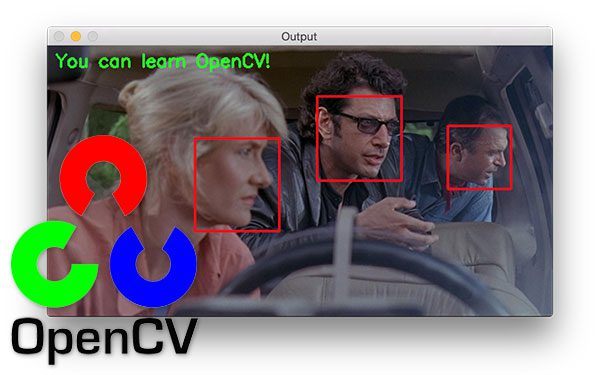

**Plataforma interactiva de OpenCV:** https://developer.opencv.fr/ui/#/onboard/demo

## **1. La imagen como datos**

Para la computadora, una imagen es una **tabla de números**: alto × ancho × 3 canales de color, cada uno entre 0 y 255.

Forma (alto, ancho, canales): (540, 960, 3)
Un píxel (fila 300, columna 200): [ 62 124 255] ← en orden Azul, Verde, Rojo


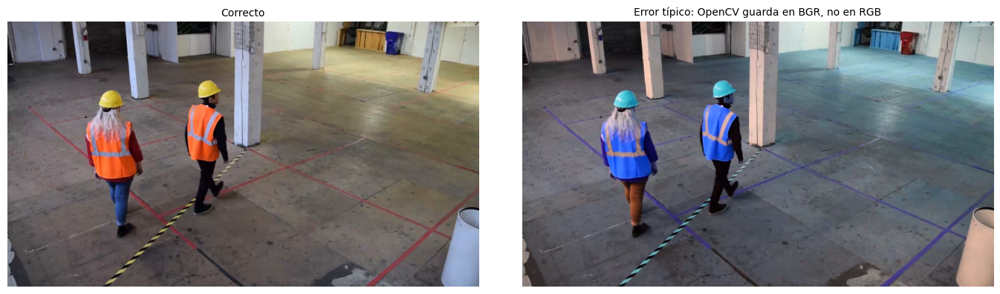

In [4]:
img = leer_frame(VIDEOS['trabajadores'], 2274, tam=(960, 540))

print('Forma (alto, ancho, canales):', img.shape)
print('Un píxel (fila 300, columna 200):', img[300, 200], '← en orden Azul, Verde, Rojo')
# BGR mostrado como RGB
mostrar([img, img[..., ::-1]], ['Correcto', 'Error típico: OpenCV guarda en BGR, no en RGB'], cols=2, ancho=14)

### Caza colores con HSV

En **HSV** el color (*H*, tono) está separado del brillo (*V*): así podemos quedarnos con un color aunque cambie la luz.

**Reto:** los valores iniciales detectan los **chalecos naranjas**. Mueve los controles hasta detectar solo los **cascos amarillos**.

In [5]:
hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)                      # H: 0-179, S/V: 0-255

@interact(H_min=entero('Tono mínimo', 0, 179, 5), H_max=entero('Tono máximo', 0, 179, 20),
          S_min=entero('Saturación mínima', 0, 255, 150), V_min=entero('Brillo mínimo', 0, 255, 150))
def cazar_color(H_min, H_max, S_min, V_min):
    mascara = cv2.inRange(hsv, (H_min, S_min, V_min), (H_max, 255, 255))
    mascara = cv2.morphologyEx(mascara, cv2.MORPH_OPEN, np.ones((5, 5), np.uint8))
    contornos, _ = cv2.findContours(mascara, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    resultado = img.copy()
    grandes = [c for c in contornos if cv2.contourArea(c) > 300]
    for c in grandes:
        x, y, w, h = cv2.boundingRect(c)
        cv2.rectangle(resultado, (x, y), (x + w, y + h), (0, 255, 0), 3)
    mostrar([mascara, resultado], ['Máscara', f'{len(grandes)} objeto(s) detectado(s)'], cols=2, ancho=14)

interactive(children=(IntSlider(value=5, continuous_update=False, description='Tono mínimo', layout=Layout(wid…

## **2. Filtros: qué hace cada uno**

Un **filtro** es una pequeña tabla de números (el **kernel**) que se desliza sobre la imagen: en cada posición multiplica, suma y escribe el resultado.

| Sin relleno | Con relleno (*padding*) | Saltando de 2 en 2 (*stride*) |
|---|---|---|
| ![](https://raw.githubusercontent.com/vdumoulin/conv_arithmetic/master/gif/no_padding_no_strides.gif) | ![](https://raw.githubusercontent.com/vdumoulin/conv_arithmetic/master/gif/same_padding_no_strides.gif) | ![](https://raw.githubusercontent.com/vdumoulin/conv_arithmetic/master/gif/no_padding_strides.gif) |
| La salida se achica | Conserva el tamaño | La salida se reduce a la mitad |

*Animaciones: [vdumoulin/conv_arithmetic](https://github.com/vdumoulin/conv_arithmetic) (MIT). Azul = imagen, verde = resultado.*

Así se ven los filtros más usados sobre la misma imagen:

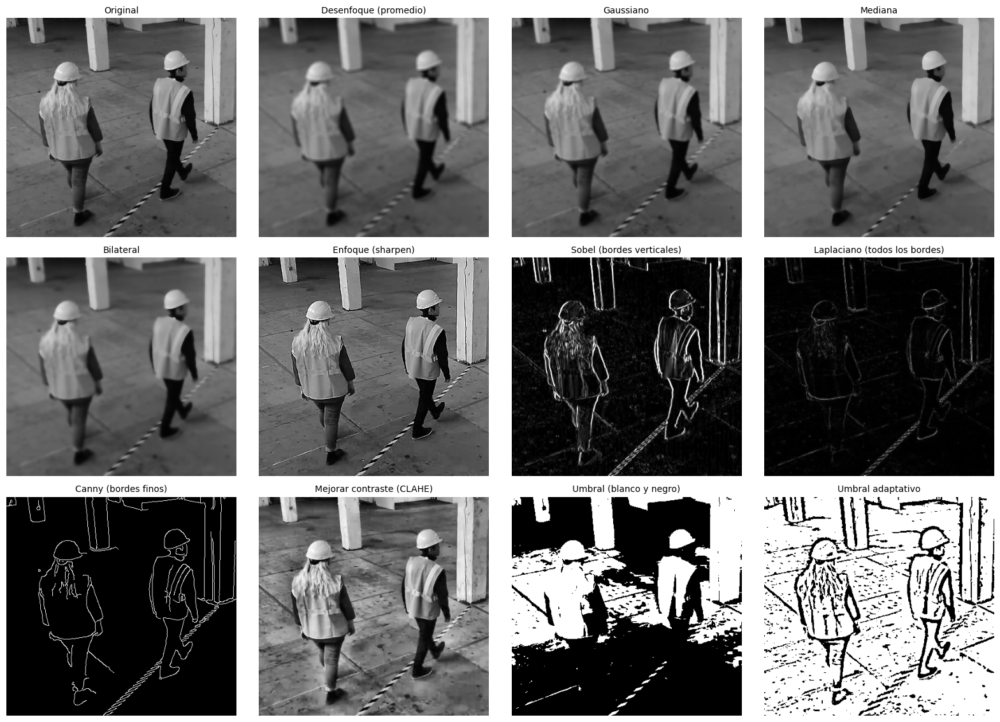

In [6]:
gris = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
zoom = gris[60:460, 100:520]                     # recorte [y, x]

FILTROS = {
    'Original':                     zoom,
    'Desenfoque (promedio)':        cv2.blur(zoom, (7, 7)),
    'Gaussiano':                    cv2.GaussianBlur(zoom, (7, 7), 0),            # sigma automático
    'Mediana':                      cv2.medianBlur(zoom, 7),
    'Bilateral':                    cv2.bilateralFilter(zoom, 9, 75, 75),         # d=9, sigmaColor=75, sigmaSpace=75
    'Enfoque (sharpen)':            cv2.filter2D(zoom, -1, np.array([[0, -1, 0], [-1, 5, -1], [0, -1, 0]])),
    'Sobel (bordes verticales)':    cv2.convertScaleAbs(cv2.Sobel(zoom, cv2.CV_32F, 1, 0)),   # dx=1, dy=0
    'Laplaciano (todos los bordes)':cv2.convertScaleAbs(cv2.Laplacian(zoom, cv2.CV_32F)),
    'Canny (bordes finos)':         cv2.Canny(cv2.GaussianBlur(zoom, (5, 5), 0), 50, 150),
    'Mejorar contraste (CLAHE)':    cv2.createCLAHE(clipLimit=3.0, tileGridSize=(8, 8)).apply(zoom),
    'Umbral (blanco y negro)':      cv2.threshold(zoom, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)[1],   # Otsu
    'Umbral adaptativo':            cv2.adaptiveThreshold(zoom, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY, 21, 5),   # bloque 21x21, C=5
}
mostrar(list(FILTROS.values()), list(FILTROS), cols=4)

### ¿Qué filtro uso y cuándo? 7 casos reales

La pregunta no es "¿qué filtro es mejor?", sino **"¿qué problema tiene mi imagen y qué quiero hacer después?"**

| # | Situación real | Lo que ves en la imagen | Filtro | ¿En qué momento? |
|---|---|---|---|---|
| 1 | Cámara de seguridad **de noche** o sensor barato | Imagen **granulada** | **Gaussiano** | **Antes** de buscar bordes |
| 2 | Cámara vieja, interferencia, **píxeles dañados** | **Puntos blancos y negros** sueltos | **Mediana** | **Primer** paso |
| 3 | Leer una **placa** o medir una pieza, con ruido | Ruido, pero los **bordes son lo importante** | **Bilateral** | Antes de bordes / OCR |
| 4 | **Contraluz**, sombras, almacén oscuro | Detalles **ocultos** en zonas oscuras | **CLAHE** | Al **inicio** |
| 5 | **Documento** fotografiado o pieza con luz de un lado | Una parte clara y otra oscura | **Umbral adaptativo** | Para separar objeto y fondo |
| 6 | Detectar por **color** o por umbral | Máscara con **huecos y puntitos** | **Morfología** (apertura + cierre) | **Antes** de contar objetos |
| 7 | Foto **un poco borrosa** para que la vea una persona | Falta nitidez | **Enfoque** | Al **final**, solo para mostrar |

### Compruébalo: elige un caso

Cada caso muestra **el problema**, lo que pasa con un **filtro equivocado** y el resultado con el **filtro correcto**.

In [7]:
from IPython.display import Markdown

rng_casos = np.random.default_rng(1)

# ruido simulado

def con_ruido_gauss(im, sigma=25):
    return np.clip(im + rng_casos.normal(0, sigma, im.shape), 0, 255).astype(np.uint8)

def con_sal_pimienta(im, p=0.04):
    sucia, u = im.copy(), rng_casos.random(im.shape)
    sucia[u < p / 2], sucia[u > 1 - p / 2] = 0, 255
    return sucia

def bordes(im):
    return cv2.Canny(im, 50, 150)

# cada caso -> (imágenes, títulos, texto)
def caso_noche():
    sucia = con_ruido_gauss(zoom)
    return ([sucia, bordes(sucia), bordes(cv2.GaussianBlur(sucia, (7, 7), 0))],
            ['Problema: imagen granulada', 'MAL: Bordes SIN filtrar: puro ruido', 'BIEN: Gaussiano y luego bordes'],
            'Si buscas bordes directamente, **cada grano de ruido parece un borde**. Suavizar primero con un **gaussiano** elimina el grano y deja los contornos reales.')

def caso_interferencia():
    sucia = con_sal_pimienta(zoom)
    return ([sucia, cv2.GaussianBlur(sucia, (5, 5), 0), cv2.medianBlur(sucia, 5)],
            ['Problema: puntos blancos y negros', 'MAL: Gaussiano: los puntos quedan como manchas', 'BIEN: Mediana: los puntos desaparecen'],
            'El gaussiano **promedia** y "reparte" cada punto en una mancha gris. La **mediana** toma el valor del medio del vecindario y **descarta** los valores extremos.')

def caso_placa():
    sucia = con_ruido_gauss(zoom, 15)
    return ([sucia, bordes(cv2.GaussianBlur(sucia, (11, 11), 0)), bordes(cv2.bilateralFilter(sucia, 9, 75, 75))],
            ['Problema: ruido + bordes importantes', 'MAL: Gaussiano fuerte: bordes borrosos e incompletos', 'BIEN: Bilateral: bordes nítidos'],
            'El gaussiano también **difumina los bordes**. El **bilateral** solo promedia píxeles **parecidos**: limpia las zonas planas y respeta los cambios bruscos. Es más lento, así que úsalo cuando los bordes importan (placas, medición de piezas).')

def caso_contraluz():
    oscura = (zoom * 0.35).astype(np.uint8)                   # subexpuesta
    return ([oscura, cv2.equalizeHist(oscura), cv2.createCLAHE(clipLimit=3.0, tileGridSize=(8, 8)).apply(oscura)],
            ['Problema: imagen oscura y sin contraste', 'REGULAR: Ecualización global: exagera y quema zonas', 'BIEN: CLAHE: mejora el contraste por zonas'],
            'La ecualización global estira el contraste de **toda** la imagen por igual. **CLAHE** lo hace **por zonas** y con un límite: recupera detalles sin quemar. Va **al inicio**, antes de detectar (también ayuda al detector de rostros de la Sección 6).')

def caso_documento():
    doc = np.full((300, 520), 235, np.uint8)
    for k, linea in enumerate(['Taller 1 - Vision Artificial', 'Filtros con OpenCV', 'Cada filtro tiene', 'su momento', 'UTPL 2026']):
        cv2.putText(doc, linea, (15, 50 + k * 55), cv2.FONT_HERSHEY_SIMPLEX, 1.0, 40, 2)
    sombra = np.tile(np.linspace(1.0, 0.25, 520), (300, 1))               # gradiente de iluminación
    foto = cv2.GaussianBlur((doc * sombra).astype(np.uint8), (3, 3), 0)
    return ([foto, cv2.threshold(foto, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)[1],
             cv2.adaptiveThreshold(foto, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY, 31, 10)],
            ['Problema: luz desigual', 'MAL: Umbral global: el lado oscuro se pierde', 'BIEN: Umbral adaptativo: todo el texto legible'],
            'El umbral **global** usa un solo valor para toda la imagen; con luz desigual, un lado queda negro. El **adaptativo** calcula un umbral **distinto para cada zona**. Es el paso previo típico para leer texto (OCR) o separar piezas del fondo.')

def caso_mascara():
    cruda = cv2.inRange(hsv, (5, 150, 150), (20, 255, 255))[100:460, 120:520]
# apertura + cierre
    limpia = cv2.morphologyEx(cv2.morphologyEx(cruda, cv2.MORPH_OPEN, np.ones((5, 5), np.uint8)),
                              cv2.MORPH_CLOSE, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (31, 31)))
    contar = lambda m: len(cv2.findContours(m, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)[0])
    return ([img[100:460, 120:520], cruda, limpia],
            ['Objetivo: contar los chalecos (hay 2)', f'MAL: Máscara directa: {contar(cruda)} "objetos"', f'BIEN: Apertura + cierre: {contar(limpia)} objetos'],
            'Una máscara por color casi nunca sale limpia: las franjas reflectivas **parten** cada chaleco. Si cuentas contornos directamente, cuentas de más. **Apertura** quita puntitos y **cierre** une las partes. Va **después** del umbral y **antes** de contar.')

def caso_borrosa():
    borrosa = cv2.GaussianBlur(zoom, (7, 7), 0)
    enfoque = np.array([[0, -1, 0], [-1, 5, -1], [0, -1, 0]])
    return ([borrosa, cv2.filter2D(borrosa, -1, enfoque), cv2.filter2D(con_ruido_gauss(borrosa, 12), -1, enfoque)],
            ['Problema: foto borrosa', 'BIEN: Enfoque: se ve más nítida', 'MAL: Enfoque con ruido: el ruido también se amplifica'],
            'El enfoque **exagera las diferencias**, incluido el ruido. Úsalo **al final** y solo para que una **persona** vea mejor la imagen, nunca antes de detectar bordes o de pasarla a un modelo.')

CASOS = {'1. Cámara nocturna (granulada)': caso_noche, '2. Interferencia (sal y pimienta)': caso_interferencia,
         '3. Placa con ruido (bordes importantes)': caso_placa, '4. Contraluz (poco contraste)': caso_contraluz,
         '5. Documento con sombra (luz desigual)': caso_documento, '6. Máscara para contar objetos': caso_mascara,
         '7. Foto borrosa (para mostrar)': caso_borrosa}

@interact(caso=widgets.Dropdown(options=list(CASOS), description='Caso:', layout=widgets.Layout(width='420px')))
def ver_caso(caso):
    imagenes, titulos, explicacion = CASOS[caso]()
    mostrar(imagenes, titulos, cols=3, ancho=17)
    display(Markdown(explicacion))

interactive(children=(Dropdown(description='Caso:', layout=Layout(width='420px'), options=('1. Cámara nocturna…

### Diseña tu propio kernel

Escribe 9 números separados por comas (fila por fila). Prueba:
* `1,1,1,1,1,1,1,1,1` con "promediar" → desenfoque
* `-1,-1,-1,0,0,0,1,1,1` → bordes horizontales
* `0,1,2,-1,0,1,-2,-1,0` → bordes diagonales

In [8]:
@interact(numeros=widgets.Text(value='0,-1,0,-1,5,-1,0,-1,0', description='Kernel 3×3:', continuous_update=False),
          promediar=widgets.Checkbox(value=False, description='Promediar (dividir por la suma)'))
def mi_kernel(numeros, promediar):
    try:
        k = np.array([float(v) for v in numeros.split(',')], np.float32).reshape(3, 3)
    except ValueError:
        print('Escribe exactamente 9 números separados por comas'); return
    if promediar and k.sum() != 0:
        k = k / k.sum()                     # normalizar
    print('Tu kernel:\n', k.round(2))
# CV_32F para no perder valores negativos
    resultado = np.clip(np.abs(cv2.filter2D(zoom, cv2.CV_32F, k)), 0, 255).astype(np.uint8)
    mostrar([zoom, resultado], ['Original', 'Con tu kernel'], cols=2, ancho=12)

interactive(children=(Text(value='0,-1,0,-1,5,-1,0,-1,0', continuous_update=False, description='Kernel 3×3:'),…

## **3. El orden importa: ruido → filtro → bordes**

Un error muy común es buscar bordes **directamente** sobre una imagen con ruido. Arma tu propio *pipeline* y observa el resultado final:
1. Elige el **ruido** que tiene la cámara.
2. (Opcional) **mejora el contraste**.
3. Elige el **filtro** de limpieza.
4. Ajusta los umbrales de **Canny**.

**Retos:** con *sal y pimienta*, ¿qué filtro deja los bordes más limpios? ¿Qué pasa si eliges "ninguno"?

In [9]:
rng = np.random.default_rng(0)

def ensuciar(imagen, ruido, cantidad):
    if ruido == 'gaussiano':
        return np.clip(imagen + rng.normal(0, cantidad, imagen.shape), 0, 255).astype(np.uint8)
    if ruido == 'sal y pimienta':
        sucia, u = imagen.copy(), rng.random(imagen.shape)
        sucia[u < cantidad / 1000], sucia[u > 1 - cantidad / 1000] = 0, 255
        return sucia
    return imagen

LIMPIEZA = {'ninguno': lambda x: x, 'gaussiano': lambda x: cv2.GaussianBlur(x, (5, 5), 0),
            'mediana': lambda x: cv2.medianBlur(x, 5), 'bilateral': lambda x: cv2.bilateralFilter(x, 9, 75, 75)}

@interact(ruido=opciones('1. Ruido', ['sal y pimienta', 'gaussiano', 'sin ruido']), cantidad=entero('Cantidad de ruido', 5, 60, 30, paso=5),
          contraste=widgets.Checkbox(value=False, description='2. Mejorar contraste (CLAHE)'),
          filtro=opciones('3. Filtro', list(LIMPIEZA)), bajo=entero('4. Canny: umbral bajo', 0, 255, 50),
          alto=entero('4. Canny: umbral alto', 0, 255, 150))
def pipeline(ruido, cantidad, contraste, filtro, bajo, alto):
    sucia = ensuciar(zoom, ruido, cantidad)
    paso2 = cv2.createCLAHE(clipLimit=3.0, tileGridSize=(8, 8)).apply(sucia) if contraste else sucia
    limpia = LIMPIEZA[filtro](paso2)
    mostrar([sucia, limpia, cv2.Canny(limpia, bajo, alto)],
            [f'Con ruido (PSNR {cv2.PSNR(zoom, sucia):.1f} dB)', f'Después del filtro {filtro} (PSNR {cv2.PSNR(zoom, limpia):.1f} dB)', 'Bordes finales (Canny)'])

interactive(children=(Dropdown(description='1. Ruido', options=('sal y pimienta', 'gaussiano', 'sin ruido'), s…

El **PSNR** indica qué tan parecida queda la imagen a la original (más alto = mejor). Regla práctica: **primero limpiar, después analizar**.

## **4. Regiones de interés, máscaras y morfología**

Una **región de interés (ROI)** limita el análisis a una parte de la imagen:
* **Rectangular:** un recorte.
* **Poligonal:** una **máscara** con la forma que queramos (un carril, una zona restringida).

Con `cv2.pointPolygonTest` sabemos si un punto está dentro de la zona; lo usaremos con YOLO en la Sección 8.

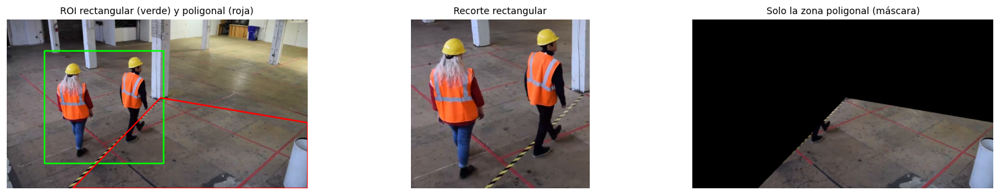

(700, 450) → dentro de la zona
(200, 300) → fuera de la zona


In [10]:
ZONA = np.array([[490, 250], [960, 330], [960, 540], [210, 540]], np.int32)   # zona restringida (coords. en 960x540)
mascara_zona = np.zeros(img.shape[:2], np.uint8)
cv2.fillPoly(mascara_zona, [ZONA], 255)

con_zona = img.copy()
cv2.rectangle(con_zona, (120, 100), (500, 460), (0, 255, 0), 3)
cv2.polylines(con_zona, [ZONA], isClosed=True, color=(0, 0, 255), thickness=3)
mostrar([con_zona, img[100:460, 120:500], cv2.bitwise_and(img, img, mask=mascara_zona)],
        ['ROI rectangular (verde) y poligonal (roja)', 'Recorte rectangular', 'Solo la zona poligonal (máscara)'])
for punto in [(700, 450), (200, 300)]:
# >0 dentro, 0 borde, <0 fuera
    print(punto, '→ dentro de la zona' if cv2.pointPolygonTest(ZONA, punto, False) >= 0 else '→ fuera de la zona')

Las máscaras casi nunca salen limpias. La **morfología** las arregla:
* **Erosión:** adelgaza y borra puntitos. **Dilatación:** engrosa y rellena.
* **Apertura:** quita puntitos sueltos. **Cierre:** rellena huecos.
* **Gradiente:** deja solo el borde.

¿Qué operación une mejor cada chaleco en una sola mancha?

In [11]:
mascara_naranja = cv2.inRange(hsv, (5, 150, 150), (20, 255, 255))[100:460, 120:520]
OPERACIONES = {'erosión': cv2.MORPH_ERODE, 'dilatación': cv2.MORPH_DILATE, 'apertura': cv2.MORPH_OPEN,
               'cierre': cv2.MORPH_CLOSE, 'gradiente': cv2.MORPH_GRADIENT}

@interact(operacion=opciones('Operación', list(OPERACIONES), 'cierre'), tamano=entero('Tamaño', 1, 31, 9, paso=2))
def morfologia(operacion, tamano):
    k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (tamano, tamano))
    resultado = cv2.morphologyEx(mascara_naranja, OPERACIONES[operacion], k)
    n = len(cv2.findContours(resultado, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)[0])
    mostrar([mascara_naranja, resultado], ['Máscara de los chalecos', f'{operacion} {tamano}×{tamano} → {n} mancha(s)'], cols=2, ancho=12)

interactive(children=(Dropdown(description='Operación', index=3, options=('erosión', 'dilatación', 'apertura',…

> **Selección de la ROI con el mouse (ejecución local):** fuera de Colab puedes usar `cv2.selectROI(imagen)` para dibujar un rectángulo, o un *callback* de clics de Matplotlib para marcar los vértices de un polígono.

## **5. Video: contar vehículos, sin filtros y con filtros**

Un video es una secuencia de imágenes, así que todo lo anterior se aplica **cuadro a cuadro**. Construimos un contador de vehículos **sin inteligencia artificial** y lo ejecutamos **dos veces sobre el mismo video**: una **sin filtros** y otra **con filtros** aplicados en el momento correcto.

| Paso | Herramienta | ¿Filtro? | Para qué |
|---|---|---|---|
| 1 | **Suavizado gaussiano** | Sí | Quitar el grano de la cámara **antes** de comparar con el fondo |
| 2 | **Sustracción de fondo** | — | Aprende cómo se ve la calle vacía y marca lo que se mueve |
| 3 | **Umbral** | Sí | Descartar las **sombras** (aparecen en gris) |
| 4 | **Apertura** | Sí | Borrar puntitos de ruido |
| 5 | **Cierre + dilatación** | Sí | Unir las partes de cada vehículo en una sola mancha |
| 6 | **Contornos** | — | Cada mancha grande es un vehículo |
| 7 | **Seguimiento + línea de conteo** | — | Dar un ID a cada mancha y contarla al cruzar la línea roja |

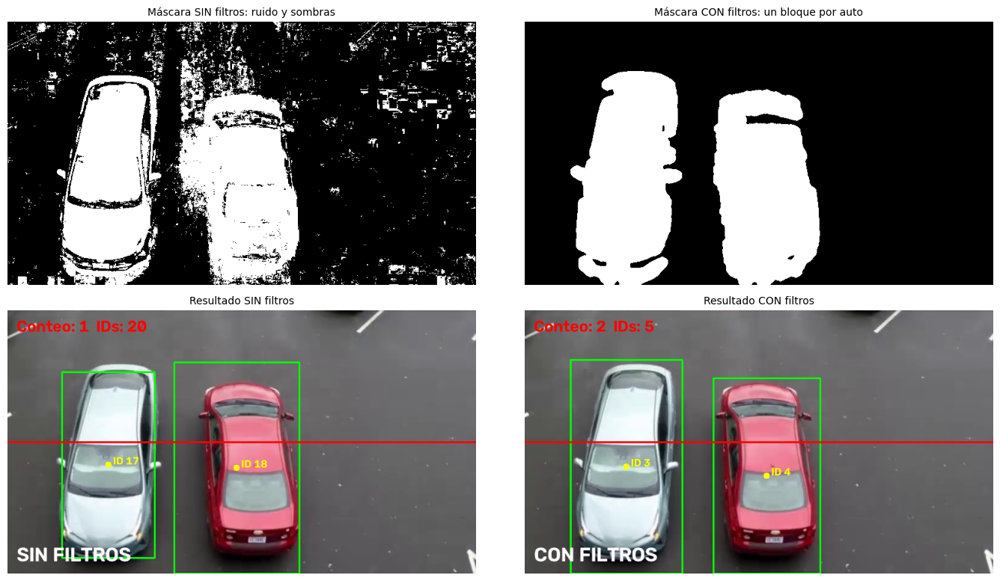

,Vehículos contados (reales: 4),IDs creados (ideal: ~4)
Sin filtros,3,40
Con filtros,4,13


In [12]:
class TrackerCentroides:
    """Tracker por centroide más cercano."""
    def __init__(self, dist_max=60):
        self.dist_max, self.objetos, self.siguiente_id = dist_max, {}, 0

    def actualizar(self, centros):
        nuevos = {}
        for c in centros:
            libres = {i: p for i, p in self.objetos.items() if i not in nuevos}
            if libres:
                i, p = min(libres.items(), key=lambda kv: np.hypot(kv[1][0] - c[0], kv[1][1] - c[1]))
                if np.hypot(p[0] - c[0], p[1] - c[1]) < self.dist_max:
                    nuevos[i] = c
                    continue
            nuevos[self.siguiente_id] = c                                         # nuevo ID
            self.siguiente_id += 1
        anteriores, self.objetos = self.objetos, nuevos
        return nuevos, anteriores

class ContadorVehiculos:
    """MOG2 + filtros + tracking + conteo por línea."""
    def __init__(self, suavizado=True, quitar_sombras=True, apertura=True, cierre=True, area_min=3000):
        self.suavizado, self.quitar_sombras, self.apertura, self.cierre, self.area_min = suavizado, quitar_sombras, apertura, cierre, area_min
        self.fondo = cv2.createBackgroundSubtractorMOG2(history=200, varThreshold=40, detectShadows=True)
        self.tracker, self.contados = TrackerCentroides(), set()
        self.k_chico = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 7))
        self.k_grande = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (15, 15))

    def mascara(self, frame):
        x = cv2.GaussianBlur(frame, (7, 7), 0) if self.suavizado else frame                   # paso 1
        m = self.fondo.apply(x)                                                                # paso 2
        m = cv2.threshold(m, 200 if self.quitar_sombras else 0, 255, cv2.THRESH_BINARY)[1]     # paso 3 (sombra = 127)
        if self.apertura:
            m = cv2.morphologyEx(m, cv2.MORPH_OPEN, self.k_chico)                              # paso 4
        if self.cierre:
            m = cv2.dilate(cv2.morphologyEx(m, cv2.MORPH_CLOSE, self.k_grande), self.k_chico, iterations=2)   # paso 5
        return m

    def procesar(self, frame, linea):
        """-> (frame anotado, máscara)"""
        m = self.mascara(frame)
        contornos, _ = cv2.findContours(m, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)           # paso 6
        cajas = [cv2.boundingRect(c) for c in contornos if cv2.contourArea(c) > self.area_min]
        actuales, anteriores = self.tracker.actualizar([(x + w // 2, y + h // 2) for (x, y, w, h) in cajas])
        vista = frame.copy()
        for i, (cx, cy) in actuales.items():                                                   # paso 7
# cruce de línea
            if i in anteriores and i not in self.contados and (anteriores[i][1] - linea) * (cy - linea) < 0:
                self.contados.add(i)
            cv2.circle(vista, (cx, cy), 5, (0, 255, 255), -1)
            cv2.putText(vista, f'ID {i}', (cx + 8, cy), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 255, 255), 2)
        for (x, y, w, h) in cajas:
            cv2.rectangle(vista, (x, y), (x + w, y + h), (0, 255, 0), 2)
        cv2.line(vista, (0, linea), (vista.shape[1], linea), (0, 0, 255), 2)
        cv2.putText(vista, f'Conteo: {len(self.contados)}  IDs: {self.tracker.siguiente_id}', (15, 35),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.9, (0, 0, 255), 2)
        return vista, m

# frames en memoria
cap = cv2.VideoCapture(VIDEOS['autos'])
fps_autos = cap.get(cv2.CAP_PROP_FPS)
frames_autos = []
while True:
    ok, frame = cap.read()
    if not ok:
        break
    frames_autos.append(frame)
cap.release()
LINEA = frames_autos[0].shape[0] // 2

sin_filtros = ContadorVehiculos(suavizado=False, quitar_sombras=False, apertura=False, cierre=False)
con_filtros = ContadorVehiculos()
alto, ancho = frames_autos[0].shape[:2]
salida = cv2.VideoWriter('output/01_conteo_sin_vs_con_filtros.mp4', cv2.VideoWriter_fourcc(*'mp4v'), fps_autos, (ancho, alto // 2))
for n, frame in enumerate(frames_autos):
    vista_sin, mascara_sin = sin_filtros.procesar(frame, LINEA)
    vista_con, mascara_con = con_filtros.procesar(frame, LINEA)
    for vista, texto in [(vista_sin, 'SIN FILTROS'), (vista_con, 'CON FILTROS')]:
        cv2.putText(vista, texto, (15, alto - 20), cv2.FONT_HERSHEY_SIMPLEX, 1.1, (255, 255, 255), 3)
    salida.write(cv2.resize(np.hstack([vista_sin, vista_con]), (ancho, alto // 2)))
    if n == 208:
        ejemplo = [mascara_sin, mascara_con, vista_sin, vista_con]
salida.release()

mostrar(ejemplo, ['Máscara SIN filtros: ruido y sombras', 'Máscara CON filtros: un bloque por auto',
                  'Resultado SIN filtros', 'Resultado CON filtros'], cols=2, ancho=14)
display(pd.DataFrame({'Vehículos contados (reales: 4)': [len(sin_filtros.contados), len(con_filtros.contados)],
                      'IDs creados (ideal: ~4)': [sin_filtros.tracker.siguiente_id, con_filtros.tracker.siguiente_id]},
                     index=['Sin filtros', 'Con filtros']))
mostrar_video('output/01_conteo_sin_vs_con_filtros.mp4', ancho=900)

**Analiza el resultado** (en el video cruzan **4 vehículos**):
* **Sin filtros**, la máscara está llena de **ruido y sombras**, y el tracker persigue cada mancha: crea **decenas de IDs**. Si el conteo sale parecido, es **por casualidad**, no porque el sistema funcione.
* **Con filtros**, cada auto es **una sola mancha**: el conteo es correcto **por las razones correctas** y hay muchos menos IDs falsos.
* Aun con filtros quedan IDs de más: la cámara **cambia de brillo** y el sistema **no sabe qué es** cada mancha (una persona o una sombra también contarían).

### Activa y desactiva cada filtro

¿Cuál es el filtro que más ayuda? ¿Qué pasa si quitas solo el umbral de sombras? (Cada cambio vuelve a procesar el video completo: espera unos segundos.)

In [13]:
@interact(suavizado=widgets.Checkbox(value=True, description='1. Suavizado'),
          quitar_sombras=widgets.Checkbox(value=True, description='3. Quitar sombras (umbral)'),
          apertura=widgets.Checkbox(value=True, description='4. Apertura'),
          cierre=widgets.Checkbox(value=True, description='5. Cierre + dilatación'))
def probar_filtros(suavizado, quitar_sombras, apertura, cierre):
    contador = ContadorVehiculos(suavizado, quitar_sombras, apertura, cierre)
    for n, frame in enumerate(frames_autos):
        vista, m = contador.procesar(frame, LINEA)
        if n == 208:
            ejemplo = [m, vista]
    mostrar(ejemplo, ['Máscara', f'Contados: {len(contador.contados)} (reales: 4) | IDs creados: {contador.tracker.siguiente_id}'], cols=2, ancho=14)

interactive(children=(Checkbox(value=True, description='1. Suavizado'), Checkbox(value=True, description='3. Q…

**Ventajas de este enfoque:** es rápido, no necesita datos de entrenamiento y es fácil de entender. Funciona bien con **cámara fija** y escenas controladas, siempre que los filtros se apliquen en el orden correcto.

# **Parte 2 — Visión artificial: rostros y YOLO26**

## **6. Detección de rostros con OpenCV (Viola-Jones)**

OpenCV incluye un detector de rostros clásico (2001), usado durante años en las cámaras digitales. Busca patrones de **rectángulos claros y oscuros**, porque la zona de los ojos es más oscura que las mejillas. Son kernels como los de la Sección 2:

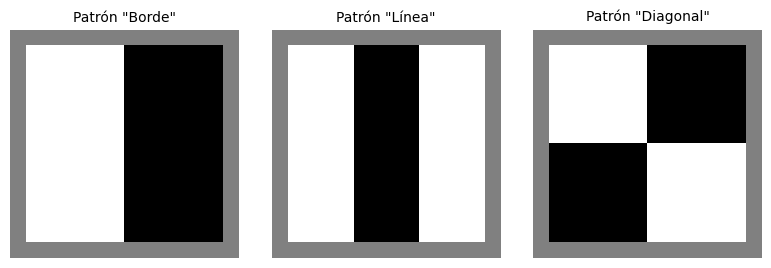

In [14]:
patrones = {'Borde': np.hstack([np.ones((24, 12)), -np.ones((24, 12))]),
            'Línea': np.hstack([np.ones((24, 8)), -np.ones((24, 8)), np.ones((24, 8))]),
            'Diagonal': np.block([[np.ones((12, 12)), -np.ones((12, 12))], [-np.ones((12, 12)), np.ones((12, 12))]])}
mostrar([np.pad(p, 2) for p in patrones.values()], [f'Patrón "{n}"' for n in patrones], cols=3, ancho=8)

# cascada Haar frontal
XML_HAAR = 'material/haarcascade_frontalface_default.xml'
if not os.path.exists(XML_HAAR):
    urllib.request.urlretrieve('https://raw.githubusercontent.com/opencv/opencv/4.x/data/haarcascades/haarcascade_frontalface_default.xml', XML_HAAR)
if not hasattr(cv2, 'CascadeClassifier'):
    raise RuntimeError('Tu OpenCV no incluye Viola-Jones. Ejecuta la celda de instalación (Sección 0) y luego '
                       'Entorno de ejecución → Reiniciar sesión, y vuelve a ejecutar el notebook.')
detector_rostros = cv2.CascadeClassifier(XML_HAAR)

**Recorre el video** y ajusta los parámetros. ¿En qué momentos pierde los rostros? (Prueba los frames 61, 244, 305 y 488.)
* **Paso entre escalas:** más pequeño = busca más tamaños de rostro, pero es más lento.
* **Vecinos mínimos:** más alto = menos falsas alarmas, pero puede perder rostros.
* **Tamaño mínimo del rostro:** ignora rostros más pequeños que este tamaño (en píxeles). Más pequeño = encuentra rostros lejanos, pero hay más riesgo de falsas alarmas.
* **Ecualizar:** mejora el contraste antes de buscar (¡un filtro aplicado en el momento correcto!).

In [15]:
@interact(frame_n=entero('Frame del video', 0, 731, 488), paso_escala=decimal('Paso entre escalas', 1.02, 1.5, 1.1, paso=0.02),
          vecinos=entero('Vecinos mínimos', 1, 15, 5), tamano_min=entero('Tamaño mínimo del rostro (px)', 10, 80, 30, paso=5),
          ecualizar=widgets.Checkbox(value=False, description='Ecualizar contraste antes'))
def rostros(frame_n, paso_escala, vecinos, tamano_min, ecualizar):
    frame = leer_frame(VIDEOS['rostros'], frame_n)
    gris_f = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
    if ecualizar:
        gris_f = cv2.equalizeHist(gris_f)
# -> [(x, y, w, h), ...]
    encontrados = detector_rostros.detectMultiScale(gris_f, scaleFactor=paso_escala, minNeighbors=vecinos, minSize=(tamano_min, tamano_min))
    for (x, y, w, h) in encontrados:
        cv2.rectangle(frame, (x, y), (x + w, y + h), (0, 255, 0), 3)
    mostrar([frame], [f'Frame {frame_n}: {len(encontrados)} rostro(s)'], cols=1, ancho=9)

interactive(children=(IntSlider(value=488, continuous_update=False, description='Frame del video', layout=Layo…

Con los valores iniciales funciona con rostros **de frente y cercanos** (frames 61 y 488), pero:
* Pierde los **2 rostros pequeños** del frame 244. Baja el **tamaño mínimo a 20** y aparecen: había que decirle que buscara rostros más pequeños.
* El rostro **de perfil y movido** (frame 305) no aparece con ningún ajuste razonable. Solo con vecinos = 1 aparece algo, pero así el detector deja de ser confiable.

 En un sistema de reconocimiento facial, **cada rostro que no se detecta es una persona que nunca será identificada**. En el Taller 2 lo compararemos con un detector moderno.

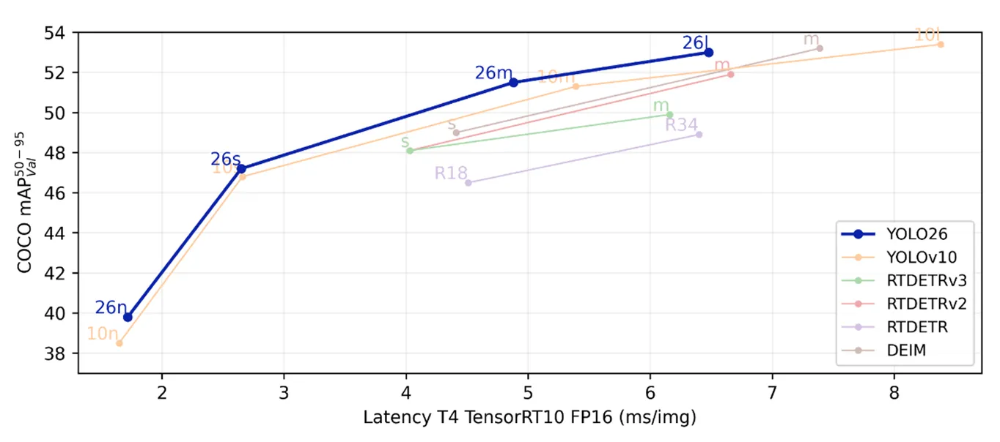

## **7. Tareas de visión artificial con YOLO26**

Los filtros de las secciones anteriores los **diseñamos nosotros**. Una **red neuronal convolucional** **aprende sus propios filtros** a partir de miles de imágenes. **YOLO** (*You Only Look Once*) es una familia de estas redes que analiza la imagen **en una sola pasada**. **YOLO26** (Ultralytics, enero de 2026) es la versión más reciente, pensada para funcionar rápido incluso **sin GPU**.

| Tarea | Pregunta que responde | Modelo |
|---|---|---|
| **Detección** | ¿Qué objetos hay y dónde? | `yolo26n.pt` |
| **Segmentación** | ¿Qué píxeles exactos ocupa cada objeto? | `yolo26n-seg.pt` |
| **Pose** | ¿Cómo está el cuerpo de cada persona? | `yolo26n-pose.pt` |
| **Clasificación** | ¿Qué hay en la imagen (una sola etiqueta)? | `yolo26n-cls.pt` |
| **Objetos rotados (OBB)** | ¿Dónde están y con qué orientación? (imágenes aéreas) | `yolo26n-obb.pt` |

Los modelos se descargan solos la primera vez. Los de detección, segmentación y pose aprendieron **80 tipos de objetos** (personas, autos, animales…) del dataset COCO.

Más información: https://docs.ultralytics.com/es/models/yolo26/

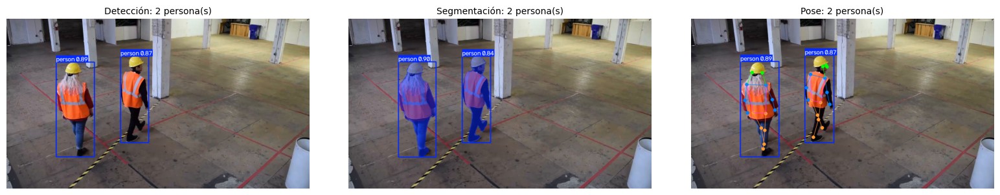

In [16]:
from ultralytics import YOLO

# modelos nano
modelos = {tarea: YOLO(archivo) for tarea, archivo in
           [('detección', 'yolo26n.pt'), ('segmentación', 'yolo26n-seg.pt'), ('pose', 'yolo26n-pose.pt'),
            ('clasificación', 'yolo26n-cls.pt'), ('obb', 'yolo26n-obb.pt')]}

vistas, titulos = [], []
for tarea in ('detección', 'segmentación', 'pose'):
    r = modelos[tarea].predict(img, conf=0.4, device=DEVICE, verbose=False)[0]
    vistas.append(r.plot())
    titulos.append(f'{tarea.capitalize()}: {len(r)} persona(s)')
mostrar(vistas, titulos)

**Clasificación** y **objetos rotados** usan otros datos de entrenamiento: el clasificador aprendió **1000 categorías** (ImageNet) y el modelo OBB, **imágenes aéreas** (barcos, aviones, vehículos…).

Found https://ultralytics.com/images/boats.jpg locally at boats.jpg


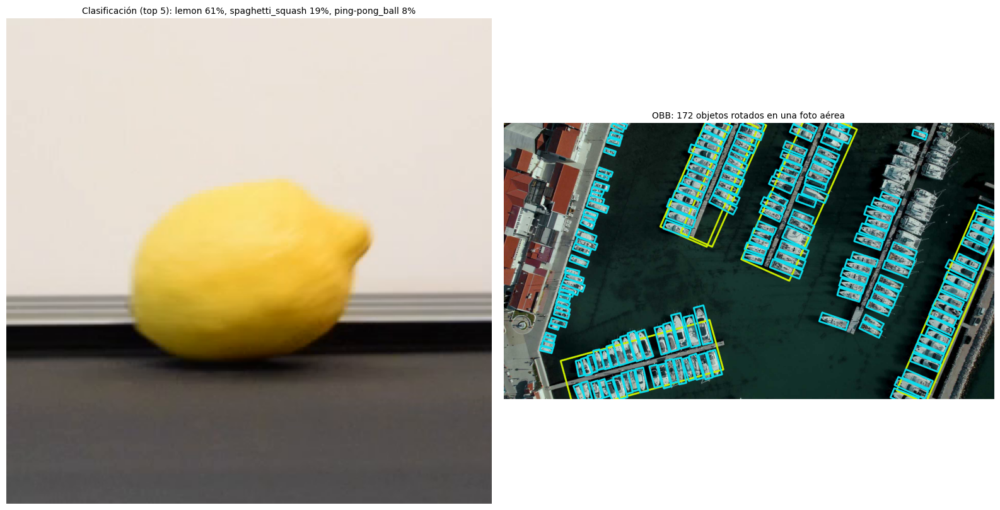

Top 5 de la clasificación: ['lemon 61%', 'spaghetti_squash 19%', 'ping-pong_ball 8%', 'butternut_squash 3%', 'tennis_ball 2%']


In [17]:
limon = leer_frame(VIDEOS['frutas'], 1020)[204:464, 465:725]
r_cls = modelos['clasificación'].predict(limon, device=DEVICE, verbose=False)[0]
top5 = [f'{r_cls.names[i]} {p:.0%}' for i, p in zip(r_cls.probs.top5, r_cls.probs.top5conf.tolist())]

r_obb = modelos['obb'].predict('https://ultralytics.com/images/boats.jpg', device=DEVICE, verbose=False)[0]

mostrar([limon, r_obb.plot(labels=False, conf=False)], ['Clasificación (top 5): ' + ', '.join(top5[:3]), f'OBB: {len(r_obb)} objetos rotados en una foto aérea'], cols=2, ancho=16)
print('Top 5 de la clasificación:', top5)

## **8. Aplicación: zona de seguridad con detección + seguimiento**

Unimos todo: la **zona poligonal** de la Sección 4, la **detección de personas** con YOLO26 y el **seguimiento** integrado de Ultralytics (la versión moderna del tracker de centroides de la Sección 5).

Para saber si una persona **pisa** la zona usamos el **punto de sus pies** (centro inferior de la caja), no el centro de la caja.

In [18]:
detector = YOLO('yolo26n.pt')                     # instancia nueva (el tracker guarda estado)
cap = cv2.VideoCapture(VIDEOS['trabajadores'])
SALTO = 3                                         # 60 fps -> 20 fps
salida = cv2.VideoWriter('output/02_zona_seguridad.mp4', cv2.VideoWriter_fourcc(*'mp4v'), cap.get(cv2.CAP_PROP_FPS) / SALTO, (960, 540))
intrusos, n = set(), 0
while n < 1800:                                   # 30 s
    ok, frame = cap.read()
    n += 1
    if not ok:
        break
    if n % SALTO:
        continue
    frame = cv2.resize(frame, (960, 540))
    r = detector.track(frame, persist=True, classes=[0], device=DEVICE, verbose=False)[0]   # clase 0 = persona
    alerta = False
    if r.boxes.id is not None:
        for (x1, y1, x2, y2), i in zip(r.boxes.xyxy.int().tolist(), r.boxes.id.int().tolist()):
            pies = ((x1 + x2) // 2, y2)
            dentro = cv2.pointPolygonTest(ZONA, pies, False) >= 0
            color = (0, 0, 255) if dentro else (0, 255, 0)
            if dentro:
                intrusos.add(i); alerta = True
            cv2.rectangle(frame, (x1, y1), (x2, y2), color, 2)
            cv2.circle(frame, pies, 6, color, -1)
            cv2.putText(frame, f'ID {i}', (x1, y1 - 8), cv2.FONT_HERSHEY_SIMPLEX, 0.7, color, 2)
    cv2.polylines(frame, [ZONA], isClosed=True, color=(0, 0, 255), thickness=2)
    if alerta:
        cv2.putText(frame, 'ALERTA: persona en zona restringida', (20, 40), cv2.FONT_HERSHEY_SIMPLEX, 1, (0, 0, 255), 3)
    cv2.putText(frame, f'Personas que ingresaron: {len(intrusos)}', (20, 520), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (255, 255, 255), 2)
    salida.write(frame)
cap.release(); salida.release()
print('IDs que ingresaron a la zona:', sorted(intrusos), '(en estos 30 s ingresan 2 personas)')
mostrar_video('output/02_zona_seguridad.mp4')

Output hidden; open in https://colab.research.google.com to view.

**Compara con la Sección 5:** YOLO **sabe que son personas** (no cualquier mancha), funciona aunque la cámara cambie de brillo y mantiene el ID de cada persona.

> **Experimenta:** agrega `tracker='bytetrack.yaml'` a `detector.track(...)` y vuelve a ejecutar. ¿Cuántos IDs aparecen para las mismas 2 personas?

# **Cierre**

**Lo que te llevas:**
1. Cada filtro tiene su momento: **mejorar contraste → limpiar ruido → analizar (bordes, umbral) → limpiar la máscara (morfología)**.
2. En video, ese mismo orden permite detectar movimiento, seguir y contar objetos sin entrenar nada.
3. OpenCV detecta **rostros frontales**, pero pierde los pequeños y los de perfil.
4. YOLO26 resuelve muchas tareas (detectar, segmentar, pose, clasificar, objetos rotados) con modelos ya entrenados.

### Próximo taller: **entrenar y evaluar YOLO26**
¿Cómo funciona YOLO por dentro? ¿Cómo medimos si detecta bien? ¿Cómo lo **entrenamos con nuestras propias imágenes** para clases que no conoce? Y el pipeline de **detección + reconocimiento facial** del proyecto final.

### Reto
1. En la Sección 1, encuentra los valores que detectan **solo los cascos amarillos**.
2. En la Sección 3, encuentra la mejor combinación de filtro y umbrales para cada tipo de ruido.
3. **(Proyecto final)** En la Sección 6, anota en qué frames OpenCV pierde rostros. Compararemos esa lista con YOLO26 en el Taller 2.
4. Cambia `classes=[0]` en la Sección 8 para vigilar otra clase y prueba con tu propio video.
5. Crea una cuenta en [Roboflow](https://roboflow.com/) para el Taller 2.

# **Anexo para casa: análisis geométrico**

## A. Transformaciones: rotar, escalar, inclinar

In [19]:
h_img, w_img = img.shape[:2]

@interact(angulo=entero('Ángulo (°)', -180, 180, 20, paso=5), escala=decimal('Escala', 0.3, 2.0, 0.8),
          inclinacion=decimal('Inclinación', -0.5, 0.5, 0.0), espejo=widgets.Checkbox(value=False, description='Espejo'))
def transformar(angulo, escala, inclinacion, espejo):
    M = cv2.getRotationMatrix2D((w_img / 2, h_img / 2), angulo, escala)
    M[0, 1] += inclinacion                                                # shear
    print('Matriz de transformación:\n', M.round(2))
    mostrar([cv2.warpAffine(cv2.flip(img, 1) if espejo else img, M, (w_img, h_img))], ['Imagen transformada'], cols=1, ancho=9)

interactive(children=(IntSlider(value=20, continuous_update=False, description='Ángulo (°)', layout=Layout(wid…

## B. Vista cenital y medición sobre el piso

Las líneas rojas del piso forman **cuadrados**, pero la cámara los ve como trapecios. Marcando las 4 esquinas de un cuadrado, OpenCV calcula la transformación (**homografía**) que endereza el piso, como si lo viéramos desde un dron.

In [20]:
piso = leer_frame(VIDEOS['trabajadores'], 600, tam=(960, 540))
celda_imagen = np.float32([[195, 275], [415, 220], [593, 300], [330, 395]])    # celda del piso en la imagen
celda_cenital = np.float32([[350, 450], [500, 450], [500, 600], [350, 600]])   # cuadrado de 150 px
H = cv2.getPerspectiveTransform(celda_imagen, celda_cenital)

cuadros = []
# animación: interpolar las esquinas
for t in list(np.linspace(0, 1, 16)) + [1] * 5 + list(np.linspace(1, 0, 16)):
    destino = np.float32((1 - t) * celda_imagen + t * celda_cenital)
    cuadro = cv2.warpPerspective(piso, cv2.getPerspectiveTransform(celda_imagen, destino), (900, 700))
    cv2.polylines(cuadro, [destino.astype(np.int32)], True, (0, 255, 255), 3)
    cuadros.append(cuadro)
guardar_gif(cuadros, 'output/vista_cenital.gif', ms=120, ancho=560)

pies = cv2.perspectiveTransform(np.float32([[[218, 439]], [[405, 394]]]), H)     # pies de los dos trabajadores
print(f'Separación de los trabajadores sobre el piso: {np.linalg.norm(pies[0, 0] - pies[1, 0]) / 150:.2f} celdas')

Output hidden; open in https://colab.research.google.com to view.

Las **columnas se deforman** porque no están sobre el piso: la transformación solo vale para ese plano. Así funcionan los sistemas que miden distancias o velocidades con una sola cámara.

## C. Encontrar un objeto aunque gire o cambie de tamaño

* **Plantilla** (`matchTemplate`): busca dónde "encaja" la foto del objeto. Falla si el objeto gira o cambia de tamaño.
* **Puntos clave (ORB):** encuentra esquinas distintivas con una "huella" que no cambia al girar, y las empareja.

In [21]:
base = leer_frame(VIDEOS['frutas'], 1260)
plantilla = base[0:420, 250:490].copy()
orb = cv2.ORB_create(nfeatures=1500)
kp1, des1 = orb.detectAndCompute(cv2.cvtColor(plantilla, cv2.COLOR_BGR2GRAY), None)

@interact(angulo=entero('Giro (°)', -90, 90, 25, paso=5), escala=decimal('Tamaño', 0.4, 1.2, 0.7))
def buscar(angulo, escala):
    hb, wb = base.shape[:2]
    escena = cv2.warpAffine(base, cv2.getRotationMatrix2D((wb / 2, hb / 2), angulo, escala), (wb, hb))

# template matching
    _, puntaje, _, (x, y) = cv2.minMaxLoc(cv2.matchTemplate(escena, plantilla, cv2.TM_CCOEFF_NORMED))
    vista_tm = escena.copy()
    cv2.rectangle(vista_tm, (x, y), (x + plantilla.shape[1], y + plantilla.shape[0]), (0, 0, 255), 4)

# ORB + RANSAC
    vista_orb, texto = escena.copy(), 'ORB: no lo encontró'
    kp2, des2 = orb.detectAndCompute(cv2.cvtColor(escena, cv2.COLOR_BGR2GRAY), None)
    if des2 is not None:
        buenos = [a for a, b in cv2.BFMatcher(cv2.NORM_HAMMING).knnMatch(des1, des2, k=2) if a.distance < 0.75 * b.distance]
        if len(buenos) >= 10:
            Hm, inl = cv2.findHomography(np.float32([kp1[m.queryIdx].pt for m in buenos]),
                                         np.float32([kp2[m.trainIdx].pt for m in buenos]), cv2.RANSAC, 5.0)
            if Hm is not None:
                ph, pw = plantilla.shape[:2]
                esquinas = cv2.perspectiveTransform(np.float32([[0, 0], [pw, 0], [pw, ph], [0, ph]]).reshape(-1, 1, 2), Hm)
                cv2.polylines(vista_orb, [esquinas.astype(np.int32)], True, (0, 255, 0), 4)
                texto = f'ORB: {int(inl.sum())} puntos coinciden'
    mostrar([vista_tm, vista_orb], [f'Plantilla: coincidencia {puntaje:.2f} (1 = perfecta)', texto], cols=2, ancho=15)

interactive(children=(IntSlider(value=25, continuous_update=False, description='Giro (°)', layout=Layout(width…